In [1]:
# --- Setup (works locally and in Google Colab) ---
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("src").exists():
    !git clone https://github.com/ArjunGopal10/privacy-preserving-synthetic-graph-generation.git
    %cd privacy-preserving-synthetic-graph-generation
    !pip install -q -r requirements.txt
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from src.visualization.plot_style import apply_style
apply_style(); plt.rcParams["figure.dpi"] = 100
%matplotlib inline

# 06 · Complete experiment — results overview
Loads the outputs of `python experiments/run_complete_experiment.py` (run it first if `results/` is empty). All numbers come from that run; nothing is typed in by hand.

In [2]:
import json
from IPython.display import Image, Markdown, display
R = ROOT / "results"
assert (R / "reports" / "experiment_report.md").exists(), "Run: python experiments/run_complete_experiment.py"
print(json.loads((R / "reports" / "complete_experiment_metadata.json").read_text())["library_versions"])
display(Markdown((R / "reports" / "experiment_report.md").read_text()))

{'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '3.0.6', 'networkx': '3.7', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'pymoo': '0.6.2', 'python-igraph': 'not installed', 'leidenalg': '0.12.0', 'pytest': '9.2.0'}


# Experiment report (auto-generated)

All numbers below were produced by the scripts in `experiments/` with the recorded seed; see `*_metadata.json` for configuration and library versions.

Only epsilon and the flip probability are formal differential-privacy quantities. Precision, recall, F1, Jaccard, modularity, NMI, etc. are empirical indicators.


## Privacy indicators

<!-- Empirical means over releases; only epsilon and p are formal DP quantities. -->
| epsilon | flip prob p | precision | recall | F1 | Jaccard | |E_H|/|E_G| | density | posterior (observed edge) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.100 | 0.475 | 0.151 | 0.522 | 0.234 | 0.133 | 3.465 | 0.482 | 0.151 |
| 0.500 | 0.378 | 0.210 | 0.620 | 0.313 | 0.186 | 2.964 | 0.412 | 0.210 |
| 1.000 | 0.269 | 0.304 | 0.741 | 0.431 | 0.275 | 2.441 | 0.339 | 0.305 |
| 2.000 | 0.119 | 0.550 | 0.887 | 0.678 | 0.514 | 1.619 | 0.225 | 0.544 |
| 3.000 | 0.047 | 0.762 | 0.953 | 0.846 | 0.734 | 1.253 | 0.174 | 0.764 |
| 5.000 | 0.007 | 0.953 | 0.997 | 0.975 | 0.951 | 1.047 | 0.146 | 0.960 |
| 8.000 | 0.000 | 0.999 | 1.000 | 0.999 | 0.999 | 1.001 | 0.139 | 0.998 |


## Community structure (Louvain)

<!-- Louvain; mean over releases; Protocol A columns use fixed P0, Protocol B columns re-detect. -->
| epsilon | Q under P0 | coverage (P0) | conductance (P0) | Q re-detected | NMI vs P0 | ARI vs P0 | # communities |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0.100 | -0.013 | 0.397 | 0.684 | 0.115 | 0.086 | -0.008 | 3.850 |
| 0.500 | 0.013 | 0.423 | 0.659 | 0.138 | 0.128 | 0.032 | 4.050 |
| 1.000 | 0.059 | 0.471 | 0.611 | 0.171 | 0.239 | 0.125 | 4.300 |
| 2.000 | 0.175 | 0.592 | 0.493 | 0.253 | 0.325 | 0.220 | 4.350 |
| 3.000 | 0.268 | 0.689 | 0.394 | 0.318 | 0.503 | 0.400 | 4.300 |
| 5.000 | 0.360 | 0.782 | 0.296 | 0.381 | 0.745 | 0.656 | 3.900 |
| 8.000 | 0.384 | 0.807 | 0.268 | 0.385 | 0.988 | 0.981 | 3.050 |


## Selected NSGA-II operating points

<!-- Selection compares against the ORIGINAL graph's modularity: data-dependent, not covered by the single-release DP guarantee. -->
| label | epsilon | expected_q | utility_fraction |
| --- | --- | --- | --- |
| smallest eps with E[Q] >= 50% of Q0 | 2.191 | 0.199 | 0.517 |
| smallest eps with E[Q] >= 80% of Q0 | 3.490 | 0.310 | 0.806 |
| smallest eps with E[Q] >= 90% of Q0 | 4.469 | 0.350 | 0.908 |
| knee (max distance from diagonal) | 3.490 | 0.310 | 0.806 |


## Baselines

<!-- epsilon-based methods shown at epsilon=2; means over releases. Edge precision/Jaccard are empirical indicators, not DP metrics. -->
| method | epsilon | releases | edge precision | Jaccard | Q under P0 | NMI vs P0 | degree KS | clustering | components | formal edge-DP |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| original | nan | 1 | 1.000 | 1.000 | 0.385 | 1.000 | 0.000 | 0.571 | 1.000 | False |
| randomized_response | 2.000 | 20 | 0.550 | 0.514 | 0.175 | 0.325 | 0.529 | 0.320 | 1.000 | True |
| laplace_topm | 2.000 | 20 | 0.325 | 0.195 | 0.077 | 0.180 | 0.234 | 0.157 | 1.500 | True |
| erdos_renyi_matched | nan | 20 | 0.141 | 0.076 | -0.024 | 0.131 | 0.257 | 0.133 | 1.150 | False |
| degree_preserving | nan | 20 | 0.327 | 0.196 | -0.033 | 0.102 | 0.000 | 0.361 | 1.000 | False |
| deletion_only | 2.000 | 20 | 1.000 | 0.880 | 0.379 | 0.698 | 0.118 | 0.450 | 1.450 | False |


## NSGA-II diagnostics

| quantity | value |
| --- | --- |
| grid_points | 500.0000 |
| grid_points_on_pareto_front | 272.0000 |
| fraction_on_front | 0.5440 |
| largest_pareto_epsilon_on_grid | 8.0756 |
| non_monotone_steps_in_E[Q]_curve | 26.0000 |
| nsga2_unique_nondominated | 40.0000 |
| nsga2_final_population | 40.0000 |
| nsga2_evaluations | 1200.0000 |
| grid_evaluations | 500.0000 |
| nsga2_hypervolume | 3.8660 |
| scratch_hypervolume | 3.8582 |
| fresh_noise_hypervolume_on_reeval | 3.8600 |


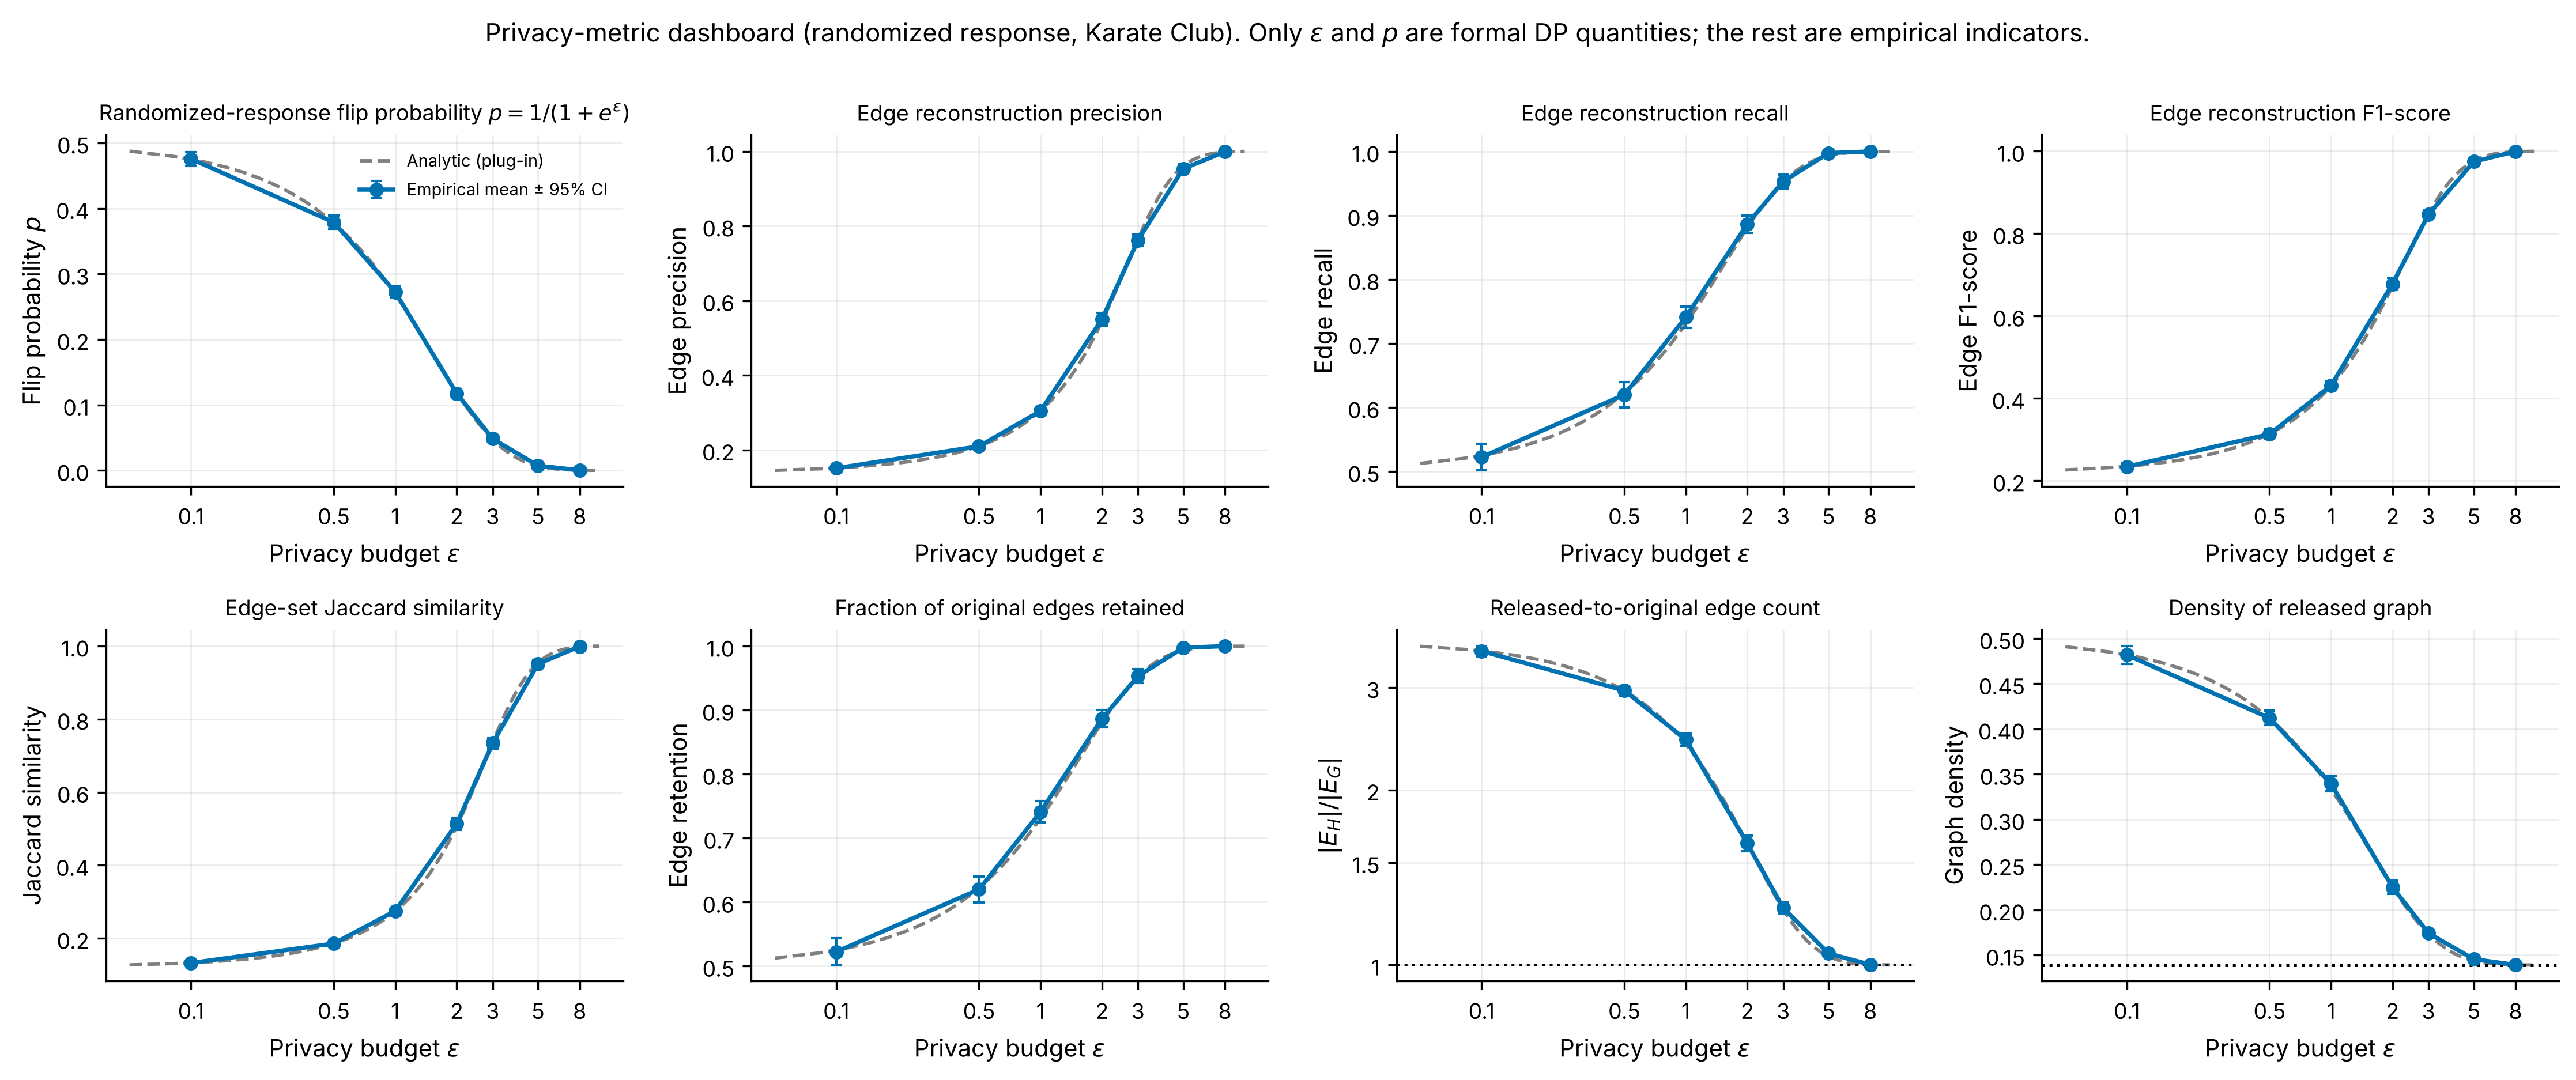

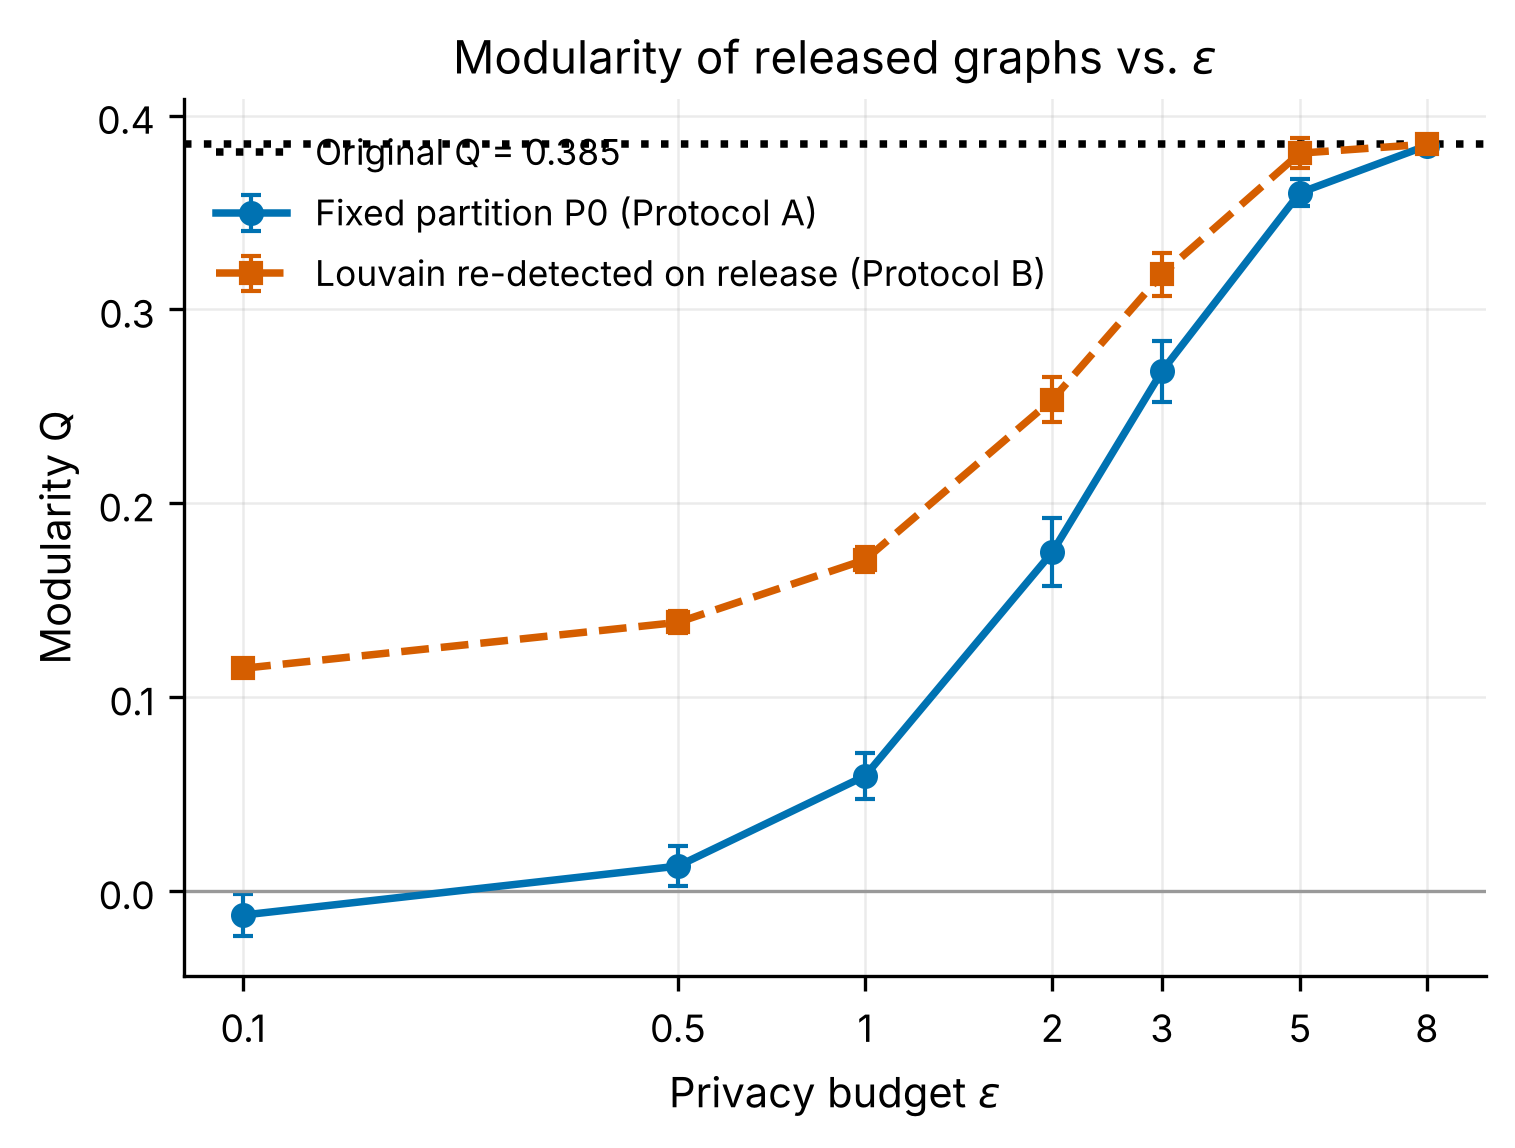

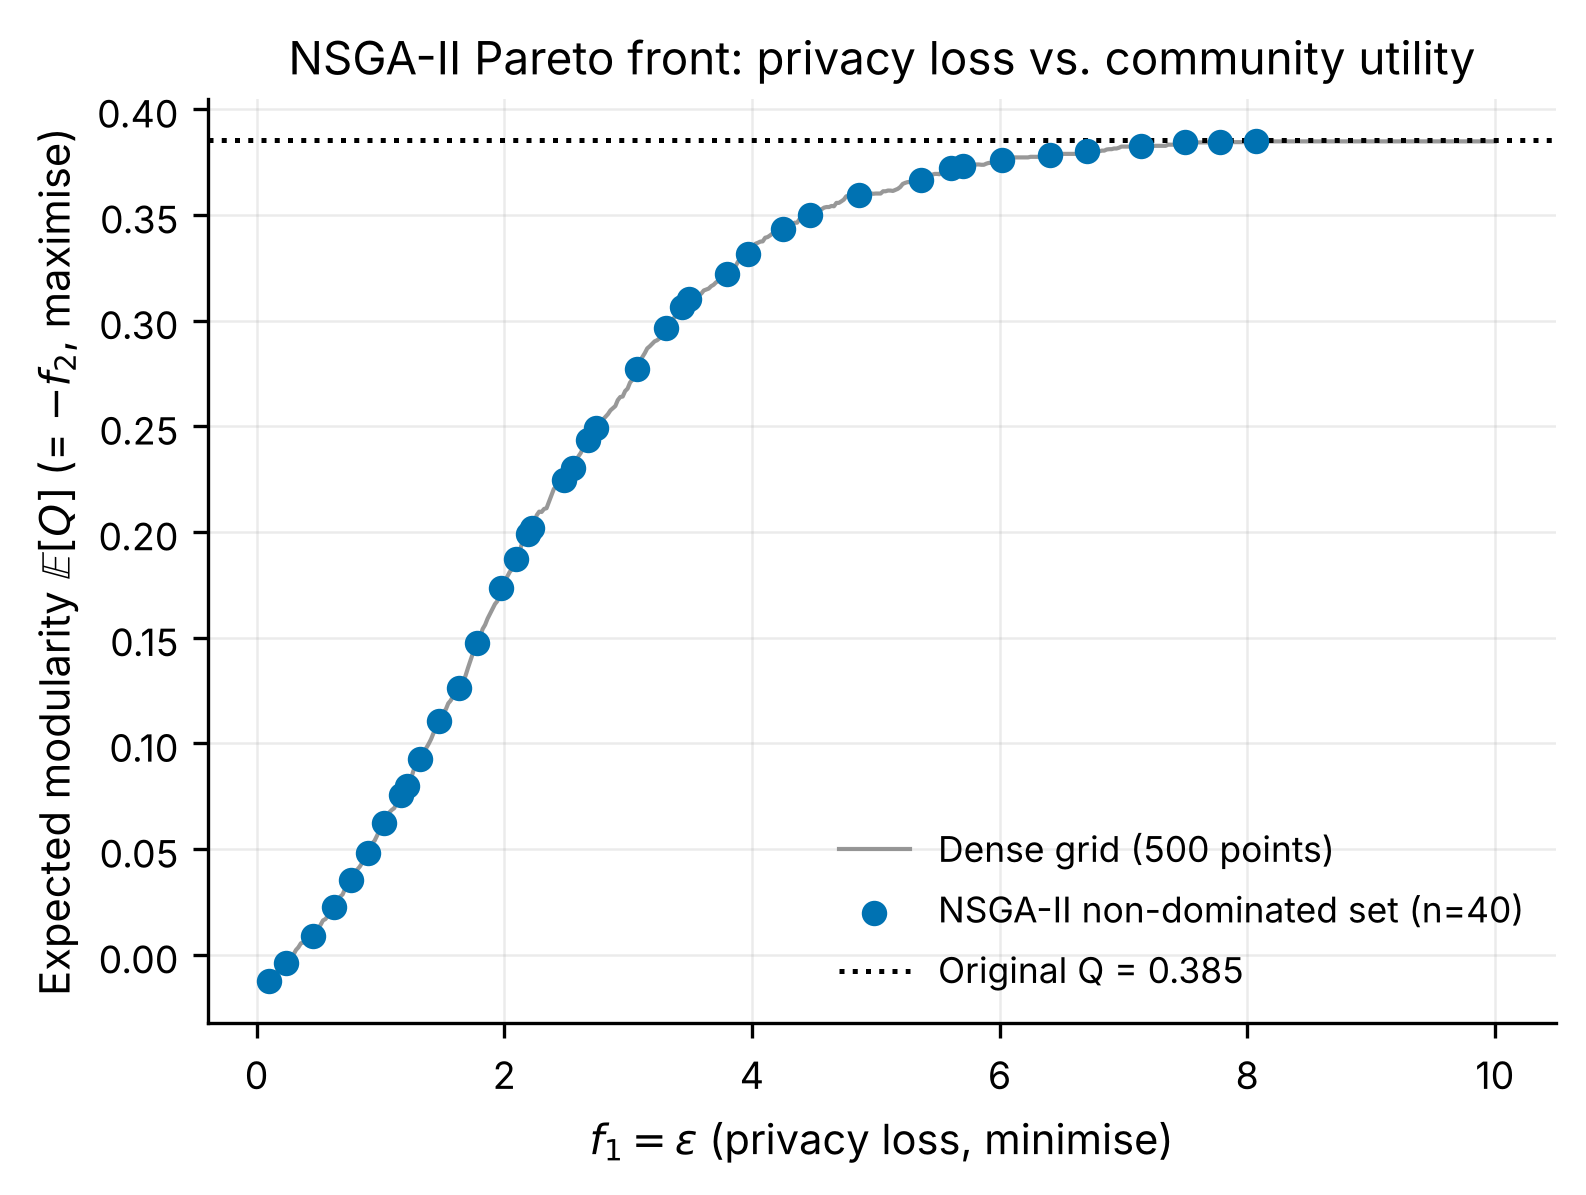

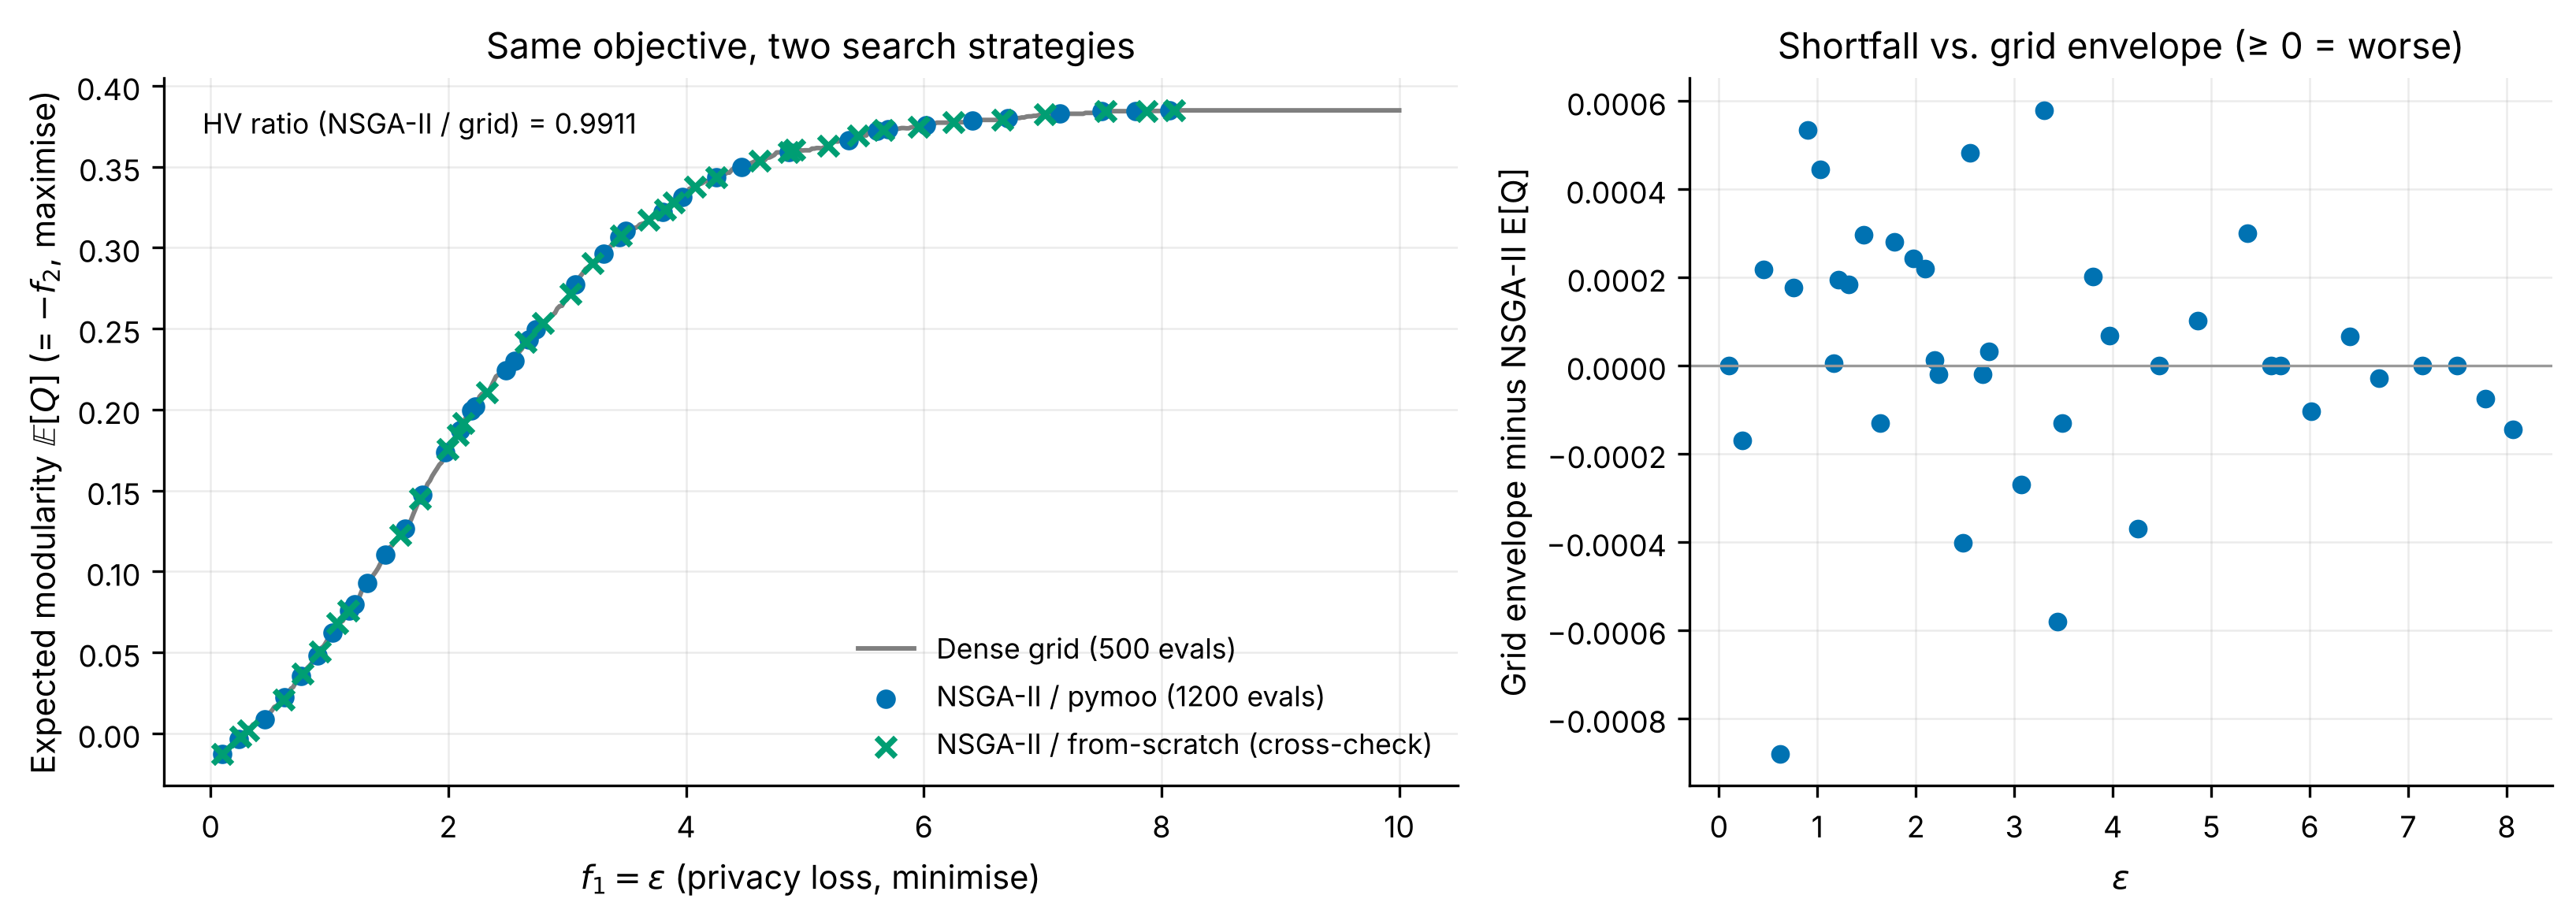

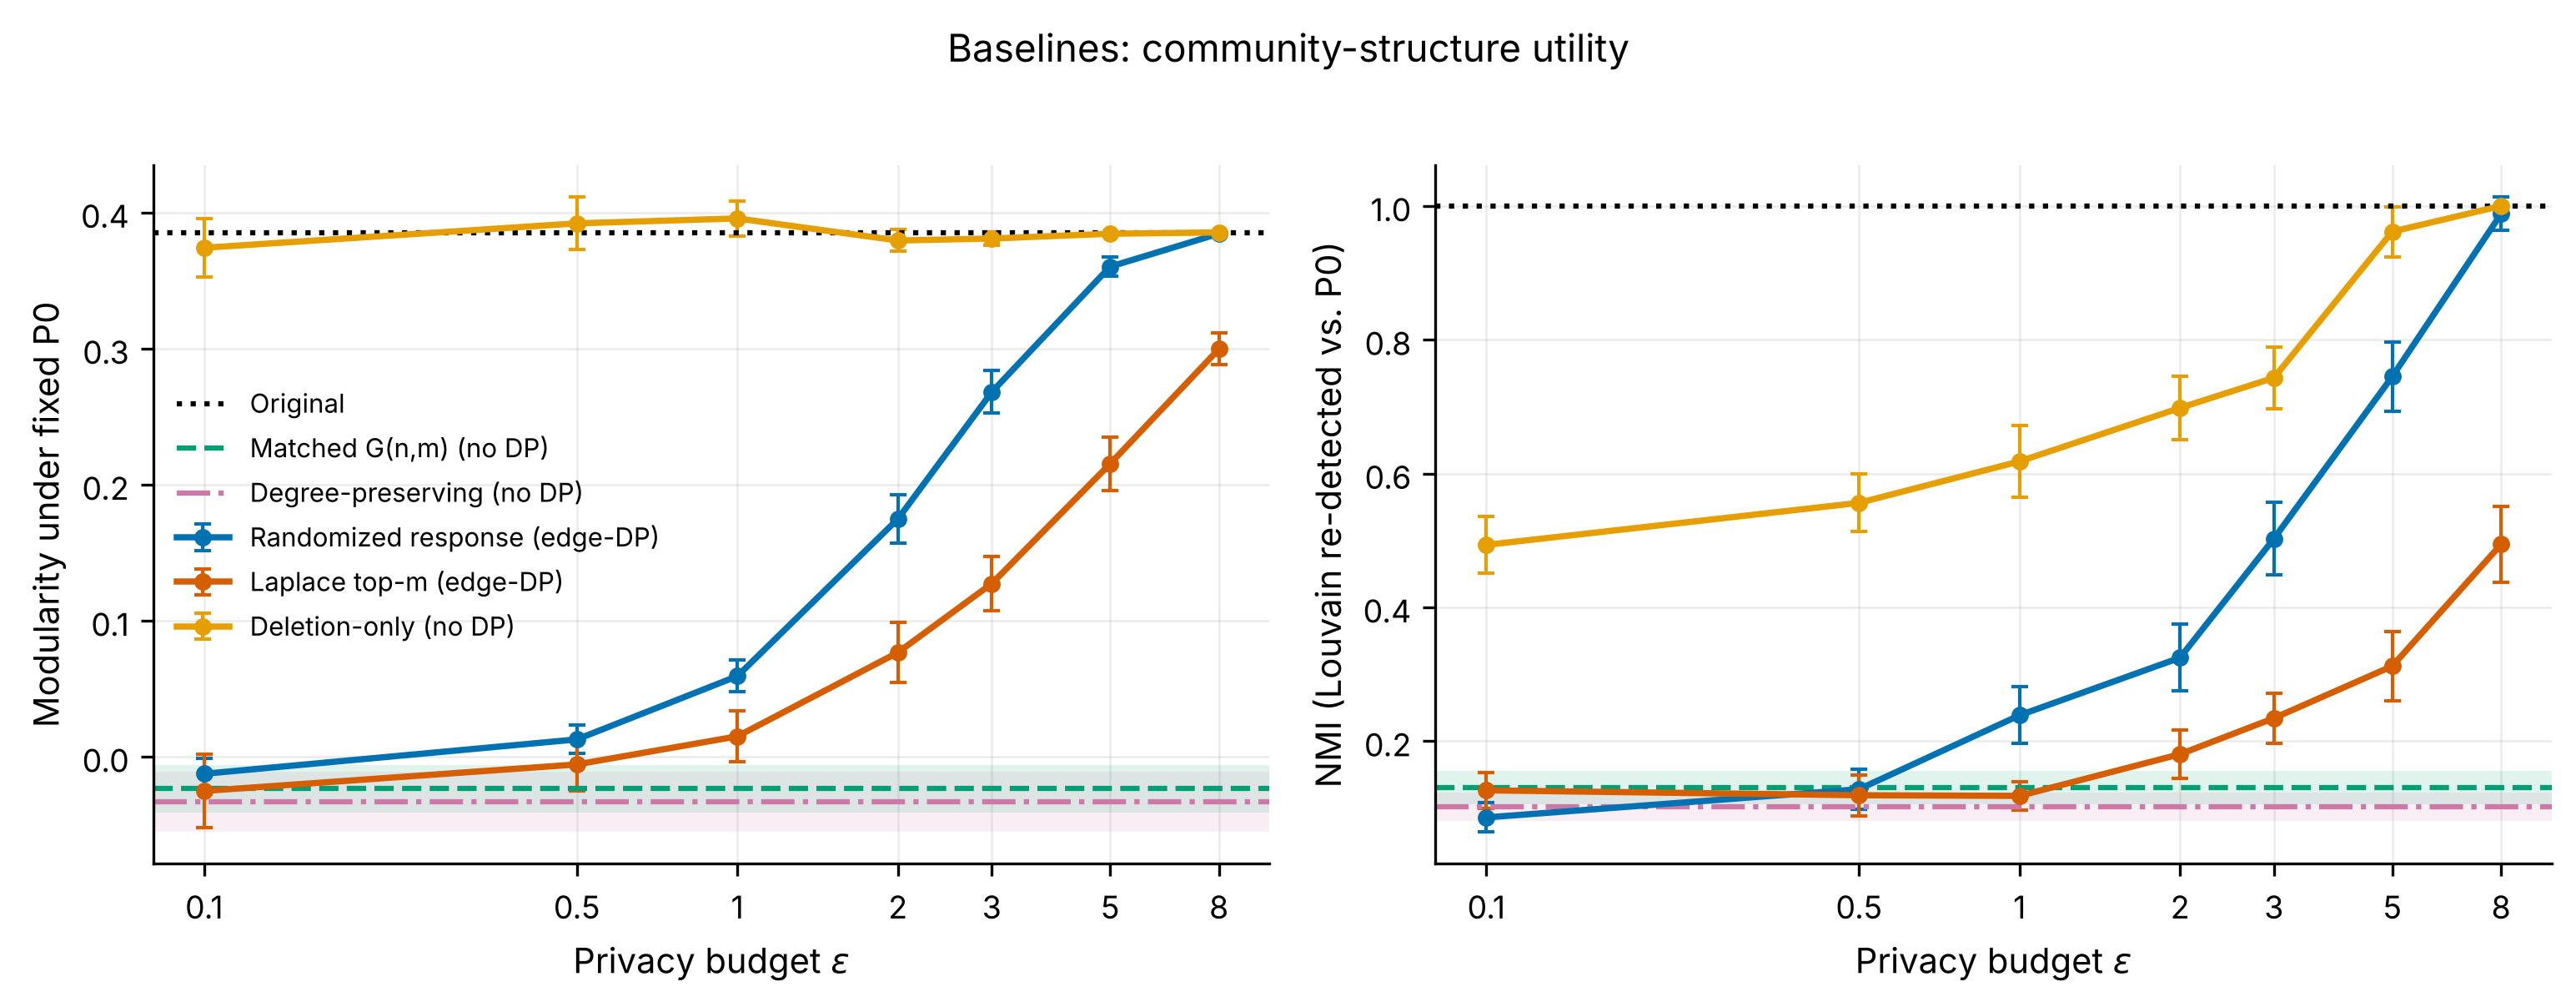

In [3]:
for f in ["fig07_privacy_metric_dashboard", "fig10_epsilon_vs_modularity", "fig18_pareto_front", "fig22_nsga2_vs_grid_search", "figX4_baseline_community_utility"]:
    display(Image(filename=str(R / "figures" / f"{f}.png"), width=800))